In [1]:

from scipy.sparse import load_npz
from pathlib import Path

import pandas as pd
import numpy as np
import re

from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score
from sklearn.model_selection import ParameterGrid

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.metrics.pairwise import cosine_similarity

import joblib
import plotly.express as px
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer

import re
from bs4 import BeautifulSoup

from spacy.lang.en.stop_words import STOP_WORDS
import en_core_web_sm

from pathlib import Path
from scipy.sparse import save_npz, load_npz
import joblib

In [3]:
data = pd.read_csv('../data/processed/sample_clean.csv')

In [4]:
pd.set_option('display.max_colwidth', None)
display(data.head(1))

,id,description_texte,details,fabric,weight,pays
0,1,"active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program .","silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2",3.7 - oz 100 % - recycled polyester gladiodor natural odor control garment . recyclable common threads recycling program,99 g 3.5 oz,Mexico


In [5]:
# sample = data.sample(n=5, random_state=42)
data = data.copy()

In [6]:
data["description_texte"] = data["description_texte"] + " " + data["details"]
display(data.head(1))

,id,description_texte,details,fabric,weight,pays
0,1,"active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program . silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2","silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2",3.7 - oz 100 % - recycled polyester gladiodor natural odor control garment . recyclable common threads recycling program,99 g 3.5 oz,Mexico


In [7]:
nlp = en_core_web_sm.load()


data["description_tokenized"] = data["description_texte"].apply(
    lambda texte: " ".join(
        token.text for token in nlp(texte) if not token.is_stop
    ) if pd.notna(texte) else texte
)

In [8]:
data.head(1)

,id,description_texte,details,fabric,weight,pays,description_tokenized
0,1,"active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program . silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2","silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2",3.7 - oz 100 % - recycled polyester gladiodor natural odor control garment . recyclable common threads recycling program,99 g 3.5 oz,Mexico,"active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program . silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2"


In [9]:
docs = []
for texte in data["description_texte"].dropna():
    doc = nlp(texte)
    print("Tokens:", [token.text for token in doc])
    print("Lemma:", [token.lemma_ for token in doc])
    print("Indices:", [token.i for token in doc])
    print("Alpha Numeric:", [token.is_alpha for token in doc])
    print("Numbers:", [token.like_num for token in doc])
    print("Stopwords restants:", [token.text for token in doc if token.is_stop])
    docs.append(doc)

Tokens: ['active', 'classic', 'boxers', '-', 's', 'reason', 'boxers', 'cult', 'favorite', '-', 'cool', ',', 'especially', 'sticky', 'situations', '.', 'quick', '-', 'drying', ',', 'lightweight', 'underwear', 'takes', 'minimal', 'space', 'travel', 'pack', '.', 'exposed', ',', 'brushed', 'waistband', 'offers', '-', '-', 'skin', 'softness', ',', '-', 'panel', 'construction', 'traditional', 'boxer', 'classic', 'fit', ',', 'functional', 'fly', '.', '3.7', '-', 'oz', '100', '%', 'recycled', 'polyester', 'moisture', '-', 'wicking', 'performance', '.', 'inseam', 'size', 'm', '4', '1/2', '.', 'recyclable', 'common', 'threads', 'recycling', 'program', '.', 'silky', 'capilene', '1', 'fabric', 'ultralight', ',', 'breathable', 'quick', '-', '-', 'dry', 'exposed', ',', 'brushed', 'elastic', 'waistband', 'comfort', '5', '-', 'panel', 'construction', 'traditional', 'boxer', 'inseam', 'size', 'm', '4', '1/2']
Lemma: ['active', 'classic', 'boxer', '-', 's', 'reason', 'boxer', 'cult', 'favorite', '-', 'c

In [10]:
textes = data["description_texte"].fillna("").astype(str)

data["description_lemmatized"] = [
    " ".join(
        token.lemma_.lower()
        for token in doc
        if not token.is_stop and token.is_alpha
    )
    for doc in nlp.pipe(textes, batch_size=100)
]

pd.set_option('display.max_colwidth', None)
data[["description_texte", "description_tokenized", "description_lemmatized"]].head(1)

,description_texte,description_tokenized,description_lemmatized
0,"active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program . silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2","active classic boxers - s reason boxers cult favorite - cool , especially sticky situations . quick - drying , lightweight underwear takes minimal space travel pack . exposed , brushed waistband offers - - skin softness , - panel construction traditional boxer classic fit , functional fly . 3.7 - oz 100 % recycled polyester moisture - wicking performance . inseam size m 4 1/2 . recyclable common threads recycling program . silky capilene 1 fabric ultralight , breathable quick - - dry exposed , brushed elastic waistband comfort 5 - panel construction traditional boxer inseam size m 4 1/2",active classic boxer s reason boxer cult favorite cool especially sticky situation quick dry lightweight underwear take minimal space travel pack expose brush waistband offer skin softness panel construction traditional boxer classic fit functional fly oz recycled polyester moisture wicke performance inseam size m recyclable common thread recycle program silky capilene fabric ultralight breathable quick dry expose brush elastic waistband comfort panel construction traditional boxer inseam size m


In [11]:
configurations = {
    "unigrammes": {
        "ngram_range": (1, 1),
        "sublinear_tf": False
    },
    "bigrammes": {
        "ngram_range": (1, 2),
        "sublinear_tf": False
    },
    "sublinear": {
        "ngram_range": (1, 1),
        "sublinear_tf": True
    }
}

In [12]:
for nom_config, config in configurations.items():
    print(f"Configuration : {nom_config}")  
    vectorizer = TfidfVectorizer(
        stop_words="english",
        max_df=0.95,
        min_df=2,
        **config
    )

    # Remplace les valeurs manquantes par une chaîne vide
    matrice_tfidf = vectorizer.fit_transform(data["description_lemmatized"].fillna(""))

    print("Dimensions :", matrice_tfidf.shape)
    print("Exemples de mots :", vectorizer.get_feature_names_out()[:20])

    processed_dir = Path("../data/processed")
    models_dir = Path("../models")

    processed_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    # Matrice TF-IDF
    save_npz(processed_dir / f"tfidf_matrix_{nom_config}_fi.npz", matrice_tfidf)

    # Vectoriseur déjà entraîné
    joblib.dump(vectorizer, models_dir / f"tfidf_vectorizer_{nom_config}_fi.joblib")

    # Correspondance : ligne de la matrice → produit
    data[["id"]].to_csv(
        processed_dir / f"tfidf_row_ids_fi.csv",
        index=False,
    )

Configuration : unigrammes
Dimensions : (500, 2020)
Exemples de mots : ['ability' 'abrasion' 'absorb' 'absorption' 'abuse' 'abusive' 'access'
 'accessory' 'accommodate' 'accomplish' 'accord' 'act' 'action' 'active'
 'activity' 'adapt' 'adaptability' 'adaptable' 'add' 'addition']
Configuration : bigrammes
Dimensions : (500, 7781)
Exemples de mots : ['ability' 'abrasion' 'abrasion articulate' 'abrasion flat'
 'abrasion protect' 'abrasion resistance' 'abrasion resistant'
 'abrasion slide' 'abrasion update' 'absorb' 'absorb high' 'absorption'
 'abuse' 'abuse cargo' 'abuse new' 'abusive' 'abusive tendency' 'access'
 'access document' 'access drop']
Configuration : sublinear
Dimensions : (500, 2020)
Exemples de mots : ['ability' 'abrasion' 'absorb' 'absorption' 'abuse' 'abusive' 'access'
 'accessory' 'accommodate' 'accomplish' 'accord' 'act' 'action' 'active'
 'activity' 'adapt' 'adaptability' 'adaptable' 'add' 'addition']


In [13]:
X_classique = load_npz(
    processed_dir / "tfidf_matrix_unigrammes_fi.npz"
)
X_sublinear = load_npz(
    processed_dir / "tfidf_matrix_sublinear_fi.npz"
)

difference = X_classique - X_sublinear
difference.eliminate_zeros()

ecart_max = (
    np.abs(difference.data).max()
    if difference.nnz else 0.0
)

print("Écart maximal entre les poids :", ecart_max)
print(
    "Matrices identiques à la tolérance choisie :",
    np.allclose(difference.data, 0, atol=1e-10, rtol=0)
)

Écart maximal entre les poids : 0.24484027064113617
Matrices identiques à la tolérance choisie : False


## Test des nouvelles features avec les 3 finalistes :

In [14]:
processed_dir = Path("../data/processed")

matrice_tfidf_unigrammes = load_npz(processed_dir / "tfidf_matrix_unigrammes_fi.npz")
matrice_tfidf_sublinear = load_npz(processed_dir / "tfidf_matrix_sublinear_fi.npz")
matrice_tfidf_bigrammes = load_npz(processed_dir / "tfidf_matrix_bigrammes_fi.npz")
ids = pd.read_csv(processed_dir / "tfidf_row_ids_fi.csv")
data = pd.read_csv(processed_dir / "sample_clean.csv")

# Il faut s'assurer que la matrice TF-IDF et les identifiants des lignes correspondent
# bien aux produits du DataFrame original.
assert matrice_tfidf_bigrammes.shape[0] == len(ids)
assert matrice_tfidf_unigrammes.shape[0] == len(data)
assert matrice_tfidf_sublinear.shape[0] == len(data)
assert ids["id"].is_unique
assert ids["id"].equals(data["id"])

In [15]:
print("Dimensions :", matrice_tfidf_bigrammes.shape)
print("Dimensions :", matrice_tfidf_unigrammes.shape)
print("Dimensions :", matrice_tfidf_sublinear.shape)

Dimensions : (500, 7781)
Dimensions : (500, 2020)
Dimensions : (500, 2020)


In [16]:
resultats = []

for matrice_tfidf, nom_matrice in [
    (matrice_tfidf_unigrammes, "unigrammes"),
    (matrice_tfidf_sublinear, "sublinear"),
    (matrice_tfidf_bigrammes, "bigrammes")
]:
    print(f"Analyse pour la matrice TF-IDF : {nom_matrice}")
    parametres = {
        "eps": np.round(np.arange(0.20, 0.98, 0.01), 2),
        "min_samples": [3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30, 50]
    }

    for params in ParameterGrid(parametres):
        labels_test = DBSCAN(
            **params,
            metric="cosine"
        ).fit_predict(matrice_tfidf)

        sans_bruit = labels_test != -1
        tailles = pd.Series(labels_test[sans_bruit]).value_counts()
        nb_clusters = len(tailles)

        score = np.nan
        if 2 <= nb_clusters < sans_bruit.sum():
            score = silhouette_score(
                matrice_tfidf[sans_bruit],
                labels_test[sans_bruit],
                metric="cosine"
            )

        resultats.append({
            "representation": nom_matrice,
            **params,
            "silhouette": score,
            "%_bruit": (~sans_bruit).mean() * 100,
            "nb_clusters": nb_clusters,
            "taille_min": tailles.min() if nb_clusters else 0,
            "%_plus_gros_cluster": (
                tailles.max() / tailles.sum() * 100
                if nb_clusters else np.nan
            )
        })


resultats = pd.DataFrame(resultats)

Analyse pour la matrice TF-IDF : unigrammes
Analyse pour la matrice TF-IDF : sublinear
Analyse pour la matrice TF-IDF : bigrammes


In [17]:
display(resultats.sort_values("silhouette", ascending=False).head(10))

,representation,eps,min_samples,silhouette,%_bruit,nb_clusters,taille_min,%_plus_gros_cluster
2185,bigrammes,0.20,4,0.924984,95.6,4,4,36.363636
2199,bigrammes,0.21,4,0.924984,95.6,4,4,36.363636
2213,bigrammes,0.22,4,0.924984,95.6,4,4,36.363636
1092,sublinear,0.20,3,0.920027,90.8,12,3,17.391304
2187,bigrammes,0.20,6,0.900615,97.2,2,6,57.142857
2186,bigrammes,0.20,5,0.900615,97.2,2,6,57.142857
2200,bigrammes,0.21,5,0.900615,97.2,2,6,57.142857
2201,bigrammes,0.21,6,0.900615,97.2,2,6,57.142857
2214,bigrammes,0.22,5,0.900615,97.2,2,6,57.142857
2215,bigrammes,0.22,6,0.900615,97.2,2,6,57.142857


In [18]:
candidats = resultats[(resultats["nb_clusters"] <= 20) & (resultats["nb_clusters"] >= 10) & resultats["silhouette"].notna()]

In [19]:
display(candidats.sort_values("silhouette", ascending=False).head(10))

,representation,eps,min_samples,silhouette,%_bruit,nb_clusters,taille_min,%_plus_gros_cluster
1092,sublinear,0.20,3,0.920027,90.8,12,3,17.391304
2184,bigrammes,0.20,3,0.897055,90.0,13,3,16.000000
2198,bigrammes,0.21,3,0.894018,89.4,14,3,15.094340
2212,bigrammes,0.22,3,0.894018,89.4,14,3,15.094340
0,unigrammes,0.20,3,0.868699,88.8,12,3,23.214286
14,unigrammes,0.21,3,0.862096,87.6,14,3,20.967742
1106,sublinear,0.21,3,0.850347,89.6,13,3,15.384615
28,unigrammes,0.22,3,0.840420,86.8,15,3,19.696970
1120,sublinear,0.22,3,0.832474,89.0,14,3,14.545455
1148,sublinear,0.24,3,0.832405,88.2,13,3,22.033898


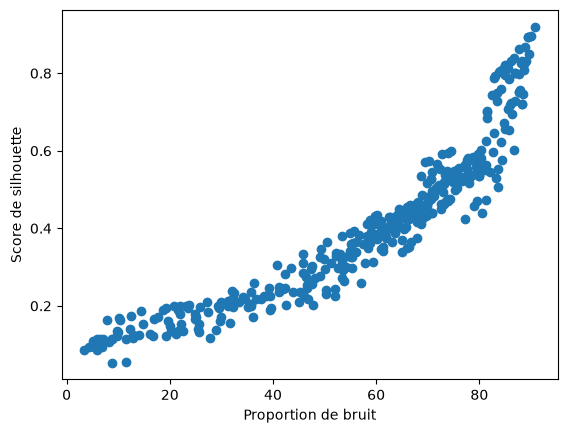

In [20]:
plt.scatter(candidats["%_bruit"], candidats["silhouette"])
plt.xlabel("Proportion de bruit")
plt.ylabel("Score de silhouette")
plt.show()

In [21]:
candidats = resultats.loc[
    resultats["nb_clusters"].between(10, 20)
    & resultats["silhouette"].notna()
].copy()

if candidats.empty:
    print("Aucun candidat dans la plage 10–20 clusters.")
    # display(resultats)
else:
    # display(candidats.sort_values(
    #     ["%_bruit", "silhouette"],
    #     ascending=[True, False]
    # ))

    fig = px.scatter(
        candidats,
        x="%_bruit",
        y="silhouette",
        color="%_plus_gros_cluster",
        hover_data=[
            "eps", "min_samples",
            "nb_clusters", "taille_min"
        ],
        title="DBSCAN — compromis entre bruit et silhouette"
    )
    fig.show()

In [22]:
candidats = candidats.loc[
    candidats["%_bruit"].between(0, 65)
    & (candidats["taille_min"] > 5)
].sort_values("%_bruit", ascending=True)

In [23]:
candidats.loc[resultats["silhouette"].between(0.2, 1)].sort_values("%_bruit", ascending=True)

,representation,eps,min_samples,silhouette,%_bruit,nb_clusters,taille_min,%_plus_gros_cluster
675,unigrammes,0.68,6,0.210872,27.2,16,6,38.736264
1781,sublinear,0.69,6,0.212436,31.2,17,6,32.848837
690,unigrammes,0.69,7,0.213660,31.4,13,6,41.399417
661,unigrammes,0.67,6,0.220261,32.2,16,6,36.283186
676,unigrammes,0.68,7,0.210006,33.4,14,6,38.438438
...,...,...,...,...,...,...,...,...
1684,sublinear,0.62,7,0.387679,63.6,12,7,31.868132
536,unigrammes,0.58,7,0.404672,64.4,11,7,31.460674
507,unigrammes,0.56,6,0.438374,64.6,13,6,31.073446
2903,bigrammes,0.71,8,0.339780,65.0,10,8,33.714286


In [25]:
finalistes = (
    candidats.loc[
        candidats["silhouette"].ge(0.2)
        & candidats["taille_min"].ge(6)
        & candidats["nb_clusters"].between(10, 20)
    ]
    .sort_values(
        ["%_bruit", "silhouette", "%_plus_gros_cluster"],
        ascending=[True, False, True]
    )
    .groupby("representation", sort=False)
    .head(1)
    .copy()
)

display(finalistes)

,representation,eps,min_samples,silhouette,%_bruit,nb_clusters,taille_min,%_plus_gros_cluster
675,unigrammes,0.68,6,0.210872,27.2,16,6,38.736264
1781,sublinear,0.69,6,0.212436,31.2,17,6,32.848837
2987,bigrammes,0.77,8,0.218212,37.6,13,7,27.884615
